# Practical 6: Uber Fare Prediction
Predict the price of an Uber ride from a pickup point to the drop-off location.

Dataset: https://www.kaggle.com/datasets/yasserh/uber-fares-dataset (`uber.csv` in the same folder)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

## Load Dataset

In [2]:
df = pd.read_csv("uber.csv")
print(df.head())
print(df.shape)
df.info()
print(df.describe())

   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647                1  
3         

## 1. Pre-Process The Dataset

In [3]:
# Drop columns that carry no information for prediction
df = df.drop(columns=["Unnamed: 0", "key"])

# Missing values
print("\nMissing values:\n", df.isnull().sum())
df = df.dropna()

# Convert pickup_datetime (object) -> datetime and extract time features
df["pickup_datetime"] = pd.to_datetime(df["pickup_datetime"], errors="coerce")
df = df.dropna(subset=["pickup_datetime"])
df["hour"] = df["pickup_datetime"].dt.hour
df["day"] = df["pickup_datetime"].dt.day
df["month"] = df["pickup_datetime"].dt.month
df["year"] = df["pickup_datetime"].dt.year
df["dayofweek"] = df["pickup_datetime"].dt.dayofweek
df = df.drop(columns=["pickup_datetime"])

# Keep only valid coordinates (latitude -90..90, longitude -180..180)
df = df[
    df["pickup_latitude"].between(-90, 90) & df["dropoff_latitude"].between(-90, 90)
    & df["pickup_longitude"].between(-180, 180) & df["dropoff_longitude"].between(-180, 180)
]

# Distance between pickup and drop-off using the Haversine formula (km)
def haversine(lon1, lat1, lon2, lat2):
    lon1, lat1, lon2, lat2 = map(np.radians, [lon1, lat1, lon2, lat2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(a))

df["distance_km"] = haversine(df["pickup_longitude"], df["pickup_latitude"],
                              df["dropoff_longitude"], df["dropoff_latitude"])

# Remove impossible values: fare <= 0, distance = 0, passengers not in 1..6
df = df[(df["fare_amount"] > 0) & (df["distance_km"] > 0) & (df["passenger_count"].between(1, 6))]
print("\nShape after pre-processing:", df.shape)


Missing values:
 fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64



Shape after pre-processing: (193644, 12)


## 2. Identify Outliers

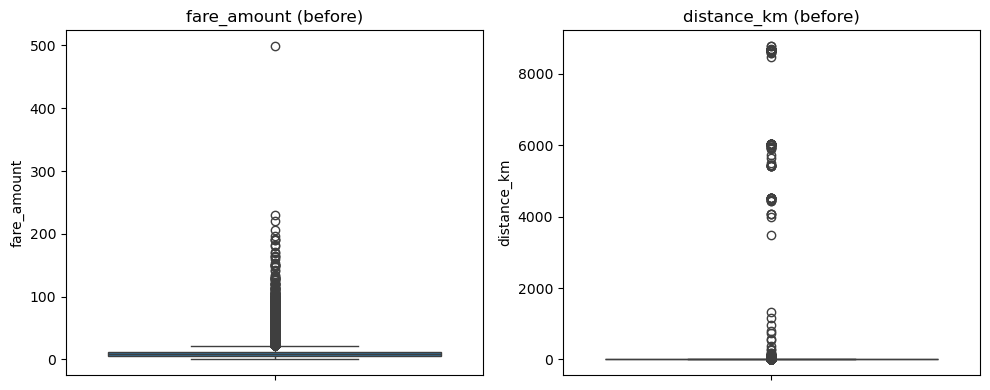

fare_amount: lower=-3.75, upper=22.25, outliers=16619
distance_km: lower=-1.95, upper=6.51, outliers=8006


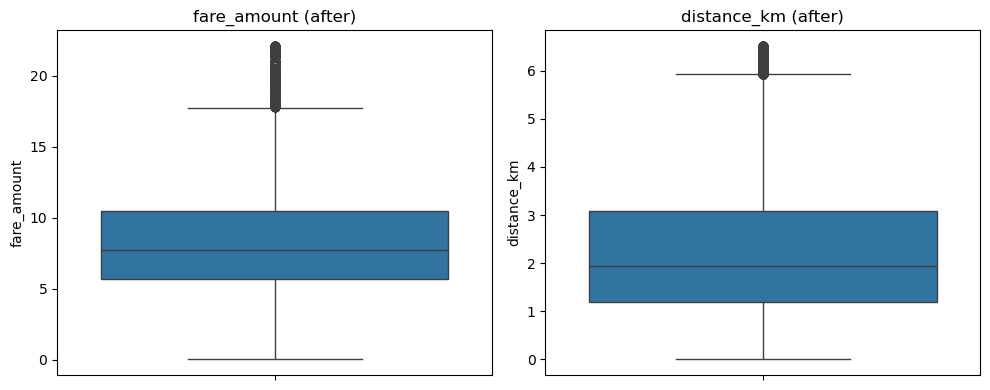

Shape after outlier removal: (169019, 12)


In [4]:
cols = ["fare_amount", "distance_km"]

plt.figure(figsize=(10, 4))
for i, c in enumerate(cols, 1):
    plt.subplot(1, 2, i)
    sns.boxplot(y=df[c])
    plt.title(f"{c} (before)")
plt.tight_layout()
plt.show()

# IQR method: outlier if value < Q1 - 1.5*IQR or value > Q3 + 1.5*IQR
for c in cols:
    Q1, Q3 = df[c].quantile(0.25), df[c].quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    n_out = ((df[c] < lower) | (df[c] > upper)).sum()
    print(f"{c}: lower={lower:.2f}, upper={upper:.2f}, outliers={n_out}")
    df = df[(df[c] >= lower) & (df[c] <= upper)]

plt.figure(figsize=(10, 4))
for i, c in enumerate(cols, 1):
    plt.subplot(1, 2, i)
    sns.boxplot(y=df[c])
    plt.title(f"{c} (after)")
plt.tight_layout()
plt.show()
print("Shape after outlier removal:", df.shape)

## 3. Check The Correlation

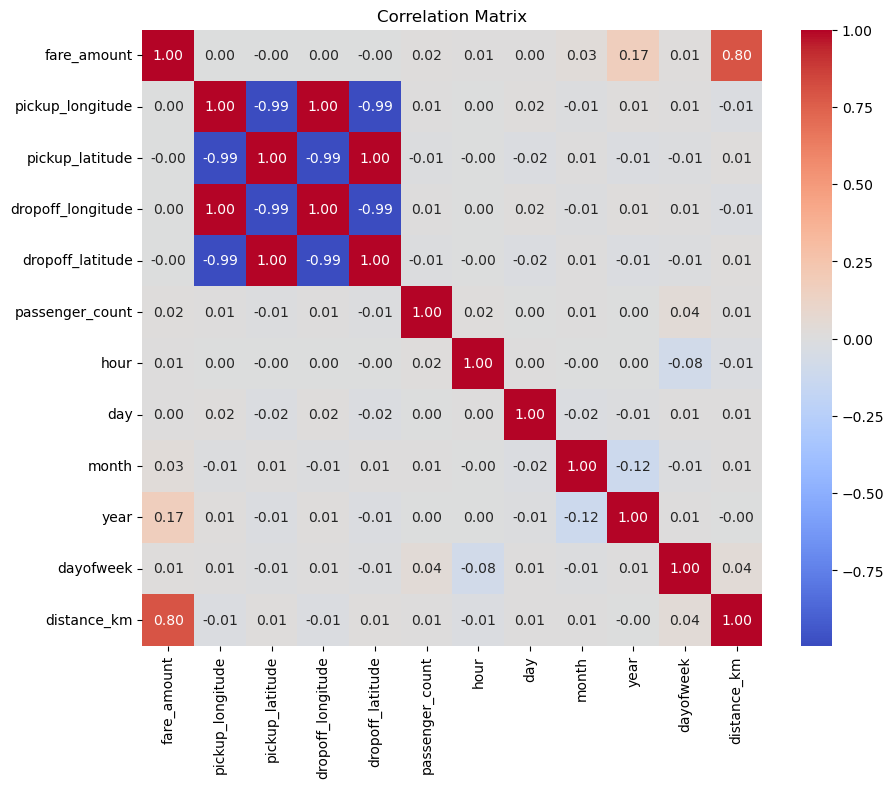


Correlation with fare_amount:
 fare_amount          1.000000
distance_km          0.795531
year                 0.173208
month                0.032687
passenger_count      0.016702
dayofweek            0.013184
hour                 0.006767
day                  0.004776
dropoff_longitude    0.002899
pickup_longitude     0.002472
pickup_latitude     -0.003313
dropoff_latitude    -0.003678
Name: fare_amount, dtype: float64


In [5]:
corr = df.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()
print("\nCorrelation with fare_amount:\n", corr["fare_amount"].sort_values(ascending=False))

## 4. Linear Regression & Random Forest

In [6]:
X = df.drop(columns=["fare_amount"])
y = df["fare_amount"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

## 5. Evaluate & Compare


Model comparison:
                        R2     MSE    RMSE     MAE
Linear Regression  0.6730  4.5233  2.1268  1.5198
Random Forest      0.7481  3.4845  1.8667  1.2986


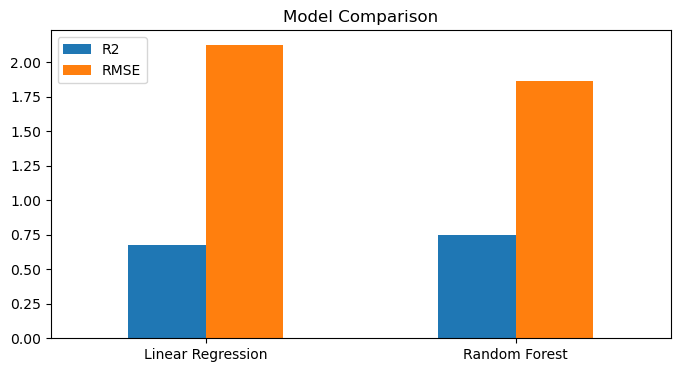


Best model: Random Forest (higher R2, lower RMSE is better)


In [7]:
def evaluate(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {"R2": r2_score(y_true, y_pred), "MSE": mse,
            "RMSE": np.sqrt(mse), "MAE": mean_absolute_error(y_true, y_pred)}

results = pd.DataFrame({
    "Linear Regression": evaluate(y_test, y_pred_lr),
    "Random Forest": evaluate(y_test, y_pred_rf),
}).T
print("\nModel comparison:\n", results.round(4))

results[["R2", "RMSE"]].plot(kind="bar", figsize=(8, 4), rot=0, title="Model Comparison")
plt.show()

best = results["R2"].idxmax()
print(f"\nBest model: {best} (higher R2, lower RMSE is better)")